# Unified optical materials data pipeline

Load, convert, validate, interpolate, evaluate, plot, and save optical response data through one material interface. This notebook covers every deliverable in the supplied task and performs no dispersion or eigenmode calculation.

**Conventions:** all API queries use angular frequency in rad/s; outputs use fields proportional to $e^{-i\omega t}$. Bulk responses return diagonal $3\times3$ tensors. Sheet conductivity returns a $2\times2$ in-plane tensor. Use `component="x"` for a single component.

**Data provenance:** Au and Ag use the [Rakić Lorentz–Drude parameterization](https://doi.org/10.1364/AO.37.005271), cross-checked against the database maintainer's [Au](https://github.com/polyanskiy/refractiveindex.info-scripts/blob/main/scripts/Rakic%201998%20-%20Au%20(LD%20model).py) and [Ag](https://github.com/polyanskiy/refractiveindex.info-scripts/blob/main/scripts/Rakic%201998%20-%20Ag%20(LD%20model).py) evaluators. **SiO2 and WTe2 are illustrative models with invented parameters, not validated physical datasets.** Other Demo materials are synthetic numerical fixtures. Their metadata carries this distinction.

From the package folder, install with `python -m pip install -e ".[notebook]"`, then open this file in Jupyter. It also works directly from the source tree. The notebook uses a temporary directory for its saved-material examples and can be rerun.

In [1]:
from pathlib import Path
import tempfile
import numpy as np
import matplotlib.pyplot as plt
import yaml
import sys
from IPython.display import display, Markdown

# Discover the checkout from either its root or notebooks folder.
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "src" / "optical_materials").is_dir():
        sys.path.insert(0, str(candidate / "src"))
        break

from optical_materials import (
    load_material, available_materials, save_material, to_omega, from_omega,
    nk_to_epsilon, epsilon_to_nk, sigma_to_epsilon, epsilon_to_sigma,
    MaterialError, RangeError, ResponseUnavailableError,
)

plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
scratch = tempfile.TemporaryDirectory(prefix="optical-material-demo-")
workspace = Path(scratch.name)
print("Imports ready. Internal frequency unit: rad/s; time convention: exp(-i*omega*t).")

Imports ready. Internal frequency unit: rad/s; time convention: exp(-i*omega*t).


## Load the database
Source formats are visible in metadata but do not affect the public response interface.

In [2]:
materials = {name: load_material(name) for name in available_materials()}
table = ["| Material | Input | Data type | Dimension | Source status |", "|---|---|---|---|---|"]
for name, mat in materials.items():
    meta = mat.metadata
    table.append(f"| {name} | {meta['input_type']} | {mat.data_type} | {mat.dimensionality}D | {meta['data_status']} |")
display(Markdown("\n".join(table)))
print("Available tensor components:", materials["WTe2"].components)

| Material | Input | Data type | Dimension | Source status |
|---|---|---|---|---|
| Ag | drude_lorentz | model | 3D | published_model |
| Au | drude_lorentz | model | 3D | published_model |
| DemoBiaxial | epsilon | tabulated | 3D | illustrative |
| DemoBulkSigma | sigma | tabulated | 3D | illustrative |
| DemoEpsilon | epsilon | tabulated | 3D | illustrative |
| DemoNK | nk | tabulated | 3D | illustrative |
| SiO2 | drude_lorentz | model | 3D | illustrative |
| WTe2 | conductivity_model | model | 2D | illustrative |

Available tensor components: ('x', 'y')


## Convert every spectral coordinate
$\omega=2\pi f=E_{\rm eV}e/\hbar=2\pi c(100\tilde\nu)$, where $\tilde\nu$ is in cm$^{-1}$. THz is also supported. Retained source units are metadata; plotting units do not alter the stored response.

In [3]:
omega_reference = to_omega(np.array([0.5, 1.0, 2.0]), "eV")
table = ["| Coordinate | Value for 1 eV |", "|---|---|"]
for unit in ("eV", "Hz", "THz", "cm-1", "rad/s"):
    coordinates = from_omega(omega_reference, unit)
    np.testing.assert_allclose(to_omega(coordinates, unit), omega_reference, rtol=3e-15)
    table.append(f"| {unit} | {coordinates[1]:.10g} |")
display(Markdown("\n".join(table)))
print("All five coordinate round trips passed.")

| Coordinate | Value for 1 eV |
|---|---|
| eV | 1 |
| Hz | 2.417989242e+14 |
| THz | 241.7989242 |
| cm-1 | 8065.543937 |
| rad/s | 1.519267448e+15 |

All five coordinate round trips passed.


## Evaluate analytical Au and Ag models
Drude and arbitrary-length Lorentz terms are evaluated directly at the requested frequencies. `parameters` exposes immutable SI values independently of the evaluator. Frequencies and damping are rad/s; Lorentz amplitudes are (rad/s)$^2$.

Au tensor shape: (500, 3, 3)
Au oscillators: 5
Au original units: eV
Au Drude frequency in rad/s: 1.1959934e+16


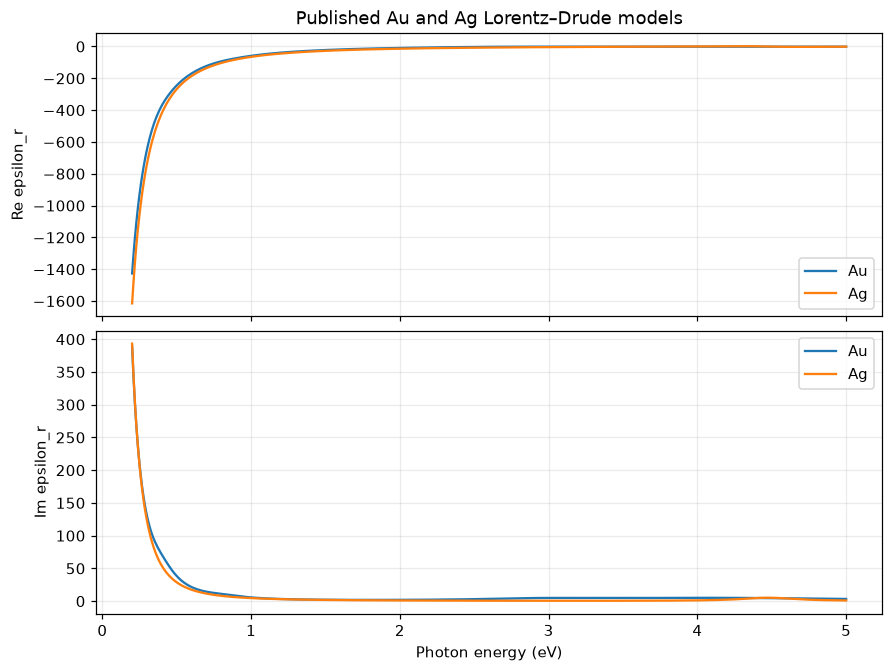

In [4]:
au, ag = materials["Au"], materials["Ag"]
energy = np.linspace(0.2, 5.0, 500)
omega = to_omega(energy, "eV")
eps_au = au.epsilon(omega)
print("Au tensor shape:", eps_au.shape)
print("Au oscillators:", len(au.parameters["iso"].oscillators))
print("Au original units:", au.metadata["original_spectral_units"])
print("Au Drude frequency in rad/s:", f"{au.parameters['iso'].omega_p:.8g}")
assert eps_au.shape == (500, 3, 3)
np.testing.assert_array_equal(eps_au[:, 0, 0], au.epsilon(omega, component="x"))

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, layout="constrained")
for mat in (au, ag):
    eps = mat.epsilon(omega, component="x")
    axes[0].plot(energy, eps.real, label=mat.name)
    axes[1].plot(energy, eps.imag, label=mat.name)
axes[0].set_title("Published Au and Ag Lorentz–Drude models")
axes[0].set_ylabel("Re epsilon_r")
axes[1].set_ylabel("Im epsilon_r")
axes[1].set_xlabel("Photon energy (eV)")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
display(fig)
plt.close(fig)

## Plot the same model in a different horizontal coordinate
`plot_epsilon` generates separate real and imaginary panels without changing material data.

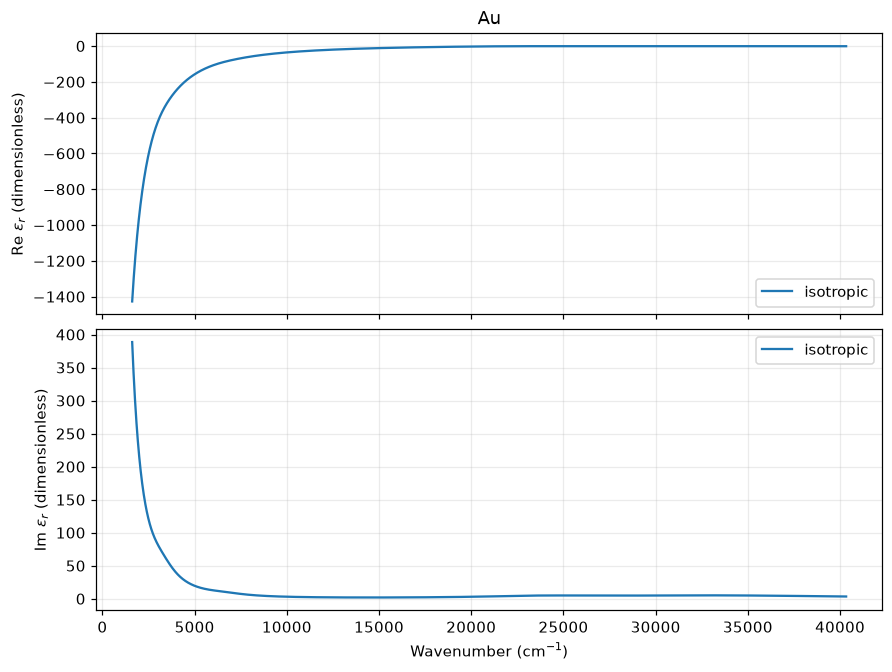

In [5]:
fig, axes = au.plot_epsilon(x_axis="cm-1")
display(fig)
plt.close(fig)
assert au.metadata["original_spectral_units"] == "eV"
assert au.omega is None  # The material remains analytical, not resampled.

## Evaluate SiO2 supplied in wavenumber units
This invented three-oscillator infrared example demonstrates conversion of frequencies **and squared-frequency amplitudes**. Replace its parameter table with a chosen experimental fit before quantitative use.

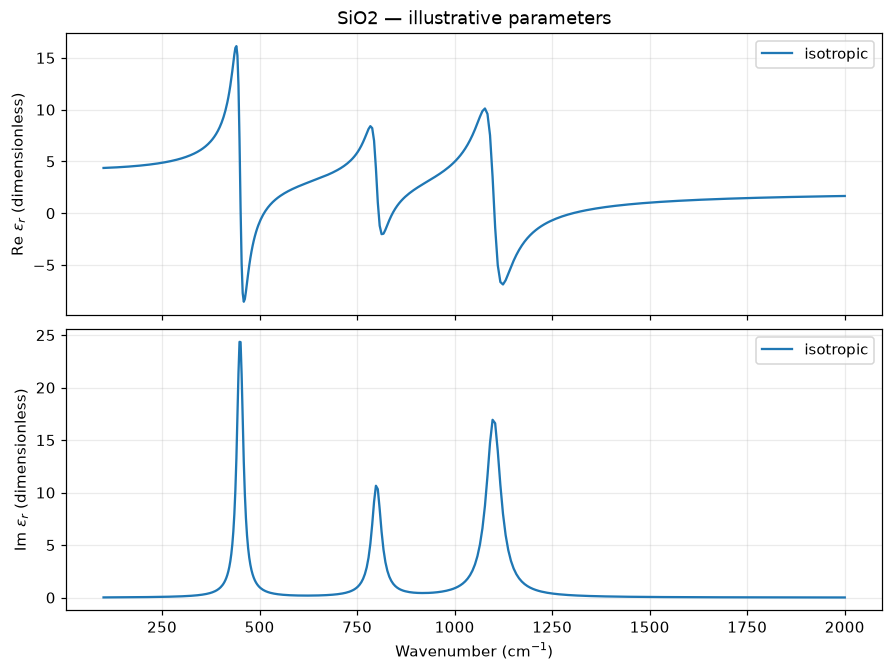

SiO2 source: Illustrative SiO2-labelled Lorentz model for infrared pipeline testing. Parameters are invented, not a published SiO2 fit.


In [6]:
silica = materials["SiO2"]
fig, axes = silica.plot_epsilon(x_axis="cm-1")
display(fig)
plt.close(fig)
print("SiO2 source:", silica.metadata["source_description"])

## Refractive index and permittivity round trips
For a nonmagnetic material, $\epsilon_r=(n+i\kappa)^2$. `epsilon_to_nk` returns the principal square root. The passive example has nonnegative n and kappa.

In [7]:
n = np.array([1.5, 2.0, 0.1])
kappa = np.array([0.02, 0.3, 4.0])
epsilon = nk_to_epsilon(n, kappa)
n_recovered, kappa_recovered = epsilon_to_nk(epsilon)
np.testing.assert_allclose(n_recovered, n, rtol=2e-14)
np.testing.assert_allclose(kappa_recovered, kappa, rtol=2e-14)
print("Original n:", n)
print("Original kappa:", kappa)
print("Converted epsilon:", epsilon)
print("Round trip passed.")

Original n: [1.5 2.  0.1]
Original kappa: [0.02 0.3  4.  ]
Converted epsilon: [  2.2496+0.06j   3.91  +1.2j  -15.99  +0.8j ]
Round trip passed.


## Two formats produce the same interpolated material
DemoNK contains n/kappa in eV. DemoEpsilon contains the same sampled permittivity in Hz. Converting n/kappa to epsilon **before interpolation** makes the two routes agree at arbitrary frequencies in the common domain.

Maximum format-equivalence error: 5.551e-16
Independent linear interpolation of real and imaginary parts passed.


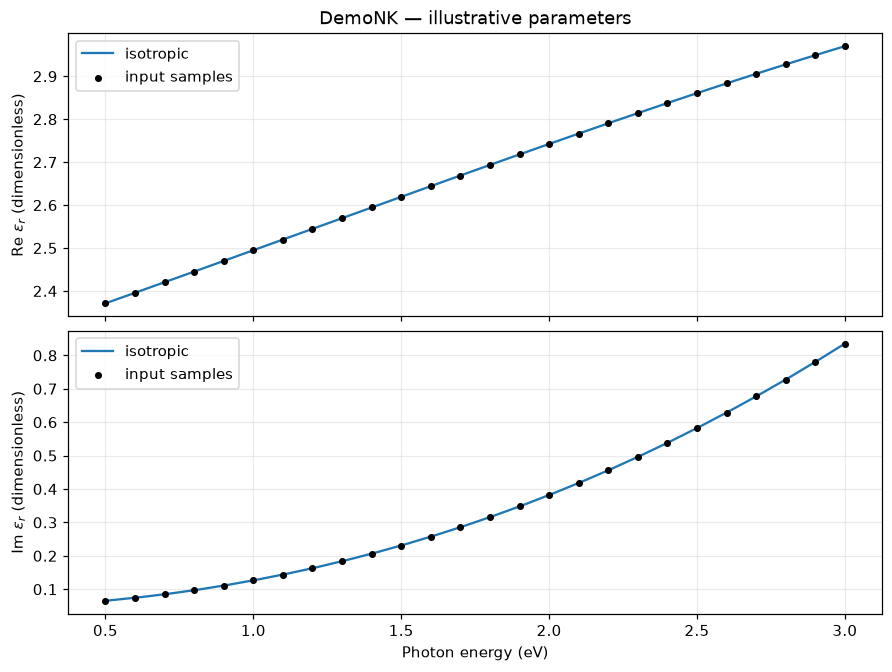

In [8]:
nk_mat, epsilon_mat = materials["DemoNK"], materials["DemoEpsilon"]
query_omega = to_omega(np.linspace(0.501, 2.999, 401), "eV")
eps_nk = nk_mat.epsilon(query_omega, component="x")
eps_direct = epsilon_mat.epsilon(query_omega, component="x")
np.testing.assert_allclose(eps_nk, eps_direct, rtol=5e-14, atol=5e-14)
max_error = np.max(np.abs(eps_nk - eps_direct))
print(f"Maximum format-equivalence error: {max_error:.3e}")

grid = nk_mat.omega
midpoint = (grid[4] + grid[5]) / 2
expected_midpoint = (nk_mat.epsilon(grid[4], "x") + nk_mat.epsilon(grid[5], "x")) / 2
np.testing.assert_allclose(nk_mat.epsilon(midpoint, "x"), expected_midpoint, rtol=2e-15)
print("Independent linear interpolation of real and imaginary parts passed.")
fig, axes = nk_mat.plot_epsilon(x_axis="eV")
for ax, part in zip(axes, ("real", "imag")):
    ax.scatter(from_omega(grid, "eV"), getattr(nk_mat.epsilon(grid, "x"), part),
               s=13, color="black", label="input samples", zorder=3)
    ax.legend()
display(fig)
plt.close(fig)

## Convert bulk conductivity and permittivity
For $e^{-i\omega t}$, $\epsilon_r=\epsilon_{bg}+i\sigma/(\epsilon_0\omega)$. The inverse depends on the same background. Conductivity derived from dielectric data is effective response relative to this background.

Maximum relative bulk-conversion error: 2.152e-16


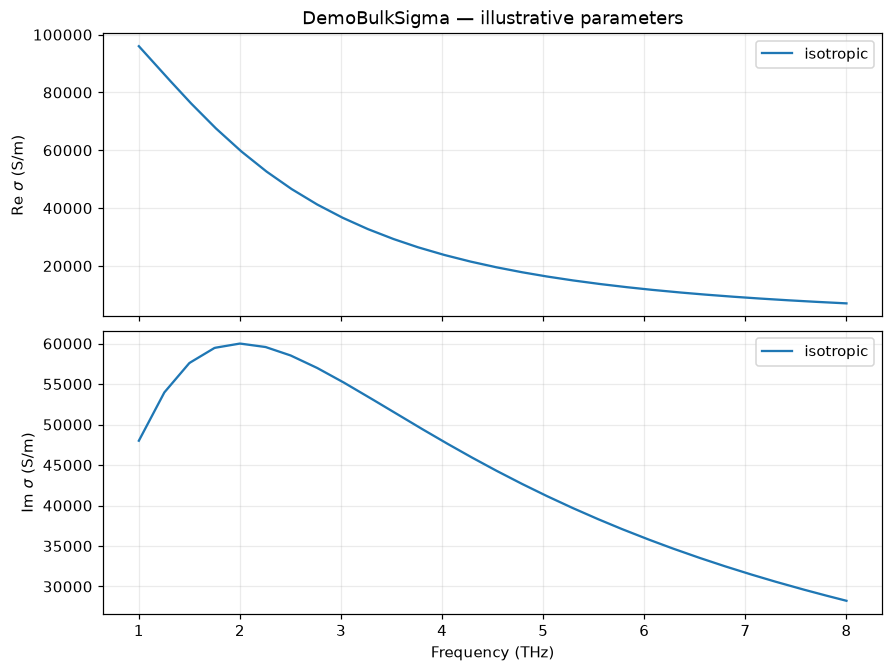

In [9]:
bulk = materials["DemoBulkSigma"]
omega_bulk = to_omega(np.linspace(1e12, 8e12, 150), "Hz")
sigma_bulk = bulk.sigma(omega_bulk, component="x")
epsilon_bulk = bulk.epsilon(omega_bulk, component="x", epsilon_bg=2.0)
np.testing.assert_allclose(epsilon_bulk, sigma_to_epsilon(sigma_bulk, omega_bulk, 2.0), rtol=1e-14)
sigma_recovered = epsilon_to_sigma(epsilon_bulk, omega_bulk, 2.0)
np.testing.assert_allclose(sigma_recovered, sigma_bulk, rtol=2e-14)
print(f"Maximum relative bulk-conversion error: {np.max(np.abs((sigma_recovered-sigma_bulk)/sigma_bulk)):.3e}")
fig, axes = bulk.plot_sigma(x_axis="THz")
display(fig)
plt.close(fig)

## Anisotropic sheet conductivity and an explicit film approximation
The illustrative WTe2 model has separate x and y Drude/Lorentz weights, in S times spectral unit. Native sheet conductivity remains in S. A film thickness is required for permittivity; its z response is the chosen background.

Native sheet tensor shape: (500, 2, 2) units: S
Expected protection: WTe2 is a 2D sheet in S. Supply thickness_m explicitly to obtain an effective film permittivity.
Effective film tensor shape: (500, 3, 3)


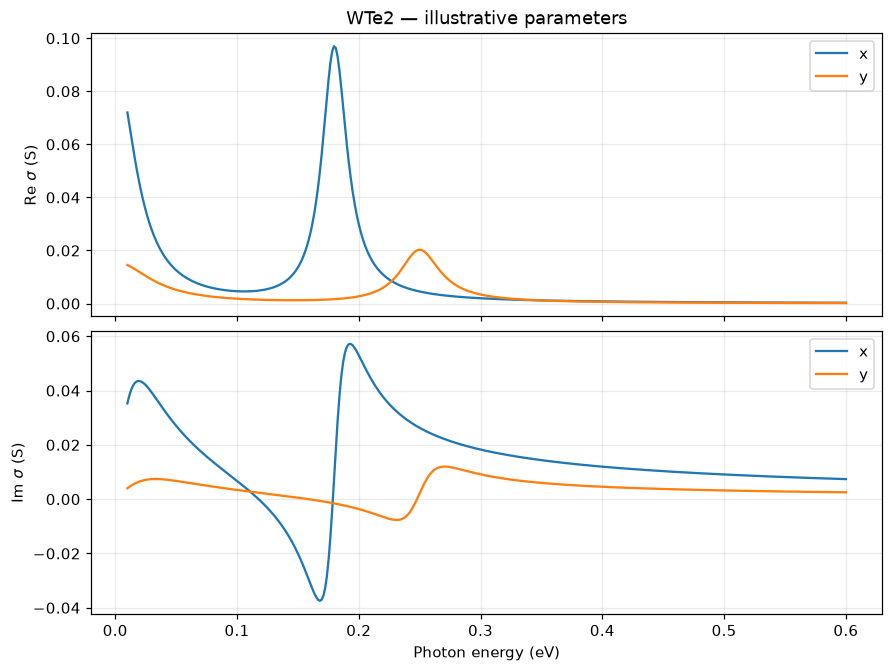

In [10]:
sheet = materials["WTe2"]
omega_sheet = to_omega(np.linspace(0.01, 0.6, 500), "eV")
sigma_sheet = sheet.sigma(omega_sheet)
print("Native sheet tensor shape:", sigma_sheet.shape, "units: S")
try:
    sheet.epsilon(omega_sheet)
except ResponseUnavailableError as exc:
    print("Expected protection:", exc)

thickness_m = 1e-9  # Explicit demonstration assumption; not a measured sample thickness.
film = sheet.epsilon(omega_sheet, thickness_m=thickness_m, epsilon_bg=2.0)
np.testing.assert_allclose(film[:, 0, 0], sigma_to_epsilon(sigma_sheet[:, 0, 0], omega_sheet, 2.0, thickness_m=thickness_m))
np.testing.assert_array_equal(film[:, 2, 2], np.full(omega_sheet.shape, 2.0))
print("Effective film tensor shape:", film.shape)
fig, axes = sheet.plot_sigma(x_axis="eV")
display(fig)
plt.close(fig)

## All principal bulk components on comparable axes
The synthetic biaxial example provides x, y, and z explicitly. No missing component is guessed.

Biaxial tensor shape: (3, 3, 3)


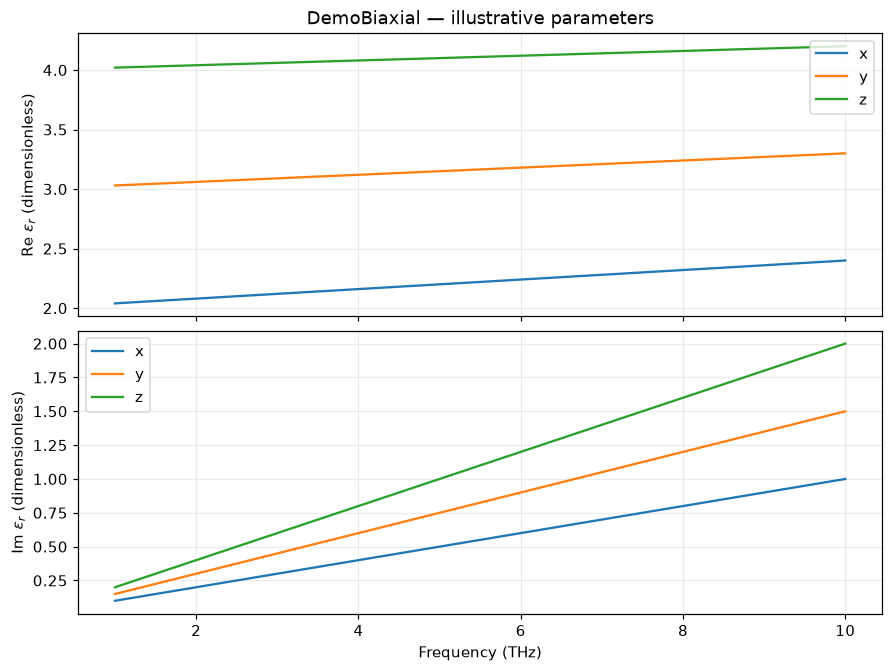

In [11]:
biaxial = materials["DemoBiaxial"]
omega_biaxial = to_omega(np.array([2., 5., 8.]), "THz")
tensor = biaxial.epsilon(omega_biaxial)
for index, component in enumerate(biaxial.components):
    np.testing.assert_allclose(tensor[:, index, index], biaxial.epsilon(omega_biaxial, component))
print("Biaxial tensor shape:", tensor.shape)
fig, axes = biaxial.plot_epsilon(x_axis="THz")
display(fig)
plt.close(fig)

## Diagnostic plot for the remaining tabulated epsilon example
Every bundled material has now appeared in a diagnostic plot, including the equivalent second input route.

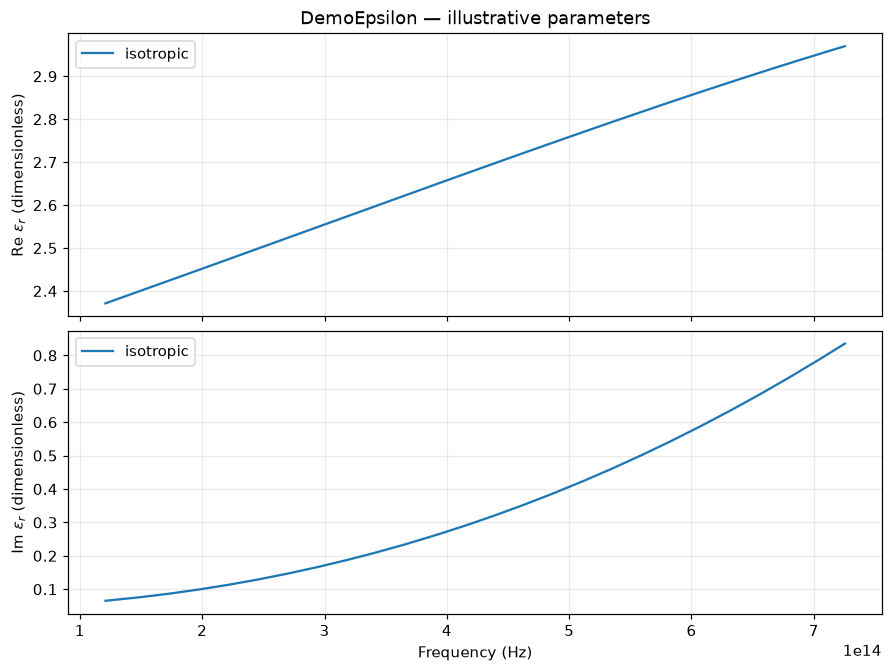

In [12]:
fig, axes = epsilon_mat.plot_epsilon(x_axis="Hz")
display(fig)
plt.close(fig)

## Save and reload every definition
The original source file, units, parameters, and provenance are retained. Models remain models after saving. Existing folders are not overwritten.

In [13]:
for name, mat in materials.items():
    destination = save_material(mat, workspace / "saved" / name)
    restored = load_material(destination)
    probe = np.geomspace(*mat.valid_frequency_range, 30)
    np.testing.assert_array_equal(restored.sigma(probe), mat.sigma(probe))
    assert restored.metadata == mat.metadata
    assert restored.data_type == mat.data_type
print("All eight definitions saved, reloaded, and checked exactly.")

All eight definitions saved, reloaded, and checked exactly.


## Add a new material using only files
The metadata mapping can be written with PyYAML, and the CSV can come from a measurement export. This example creates a new folder in a custom database and does not edit or register any core code.

In [14]:
custom_database = workspace / "my-materials"
new_folder = custom_database / "MyNewGlass"
new_folder.mkdir(parents=True)
definition = {
    "schema_version": 1,
    "name": "MyNewGlass",
    "dimensionality": 3,
    "symmetry": "isotropic",
    "components": ["iso"],
    "input_type": "nk",
    "spectral_units": "eV",
    "response_units": "dimensionless",
    "time_convention": "exp(-i*omega*t)",
    "source_description": "Illustrative new-material notebook fixture; not measured data.",
    "data_status": "illustrative",
    "valid_frequency_range": {"min": 1.0, "max": 2.0, "unit": "eV"},
    "data_file": "data.csv",
}
(new_folder / "material.yaml").write_text(yaml.safe_dump(definition, sort_keys=False), encoding="utf-8")
(new_folder / "data.csv").write_text("energy,n,kappa\n1.0,1.5,0.02\n1.5,1.55,0.03\n2.0,1.6,0.04\n", encoding="utf-8")
new_material = load_material("MyNewGlass", database=custom_database)
np.testing.assert_allclose(new_material.epsilon(to_omega(1.5,"eV"),"x"), (1.55+0.03j)**2)
print(new_material)
print("Custom database discovery:", available_materials(custom_database))
assert "MyNewGlass" in available_materials(custom_database)

Material(name='MyNewGlass', data_type='tabulated', dimensionality=3, components=('x', 'y', 'z'))
Custom database discovery: ['Ag', 'Au', 'DemoBiaxial', 'DemoBulkSigma', 'DemoEpsilon', 'DemoNK', 'MyNewGlass', 'SiO2', 'WTe2']


## Plain-language errors
Out-of-range queries and unknown units fail instead of silently extrapolating or assuming a convention. The regression suite also checks duplicated points, missing imaginary values, missing axes, nonmonotonic tables, and inconsistent model units.

In [15]:
for label, operation in [
    ("Unknown units", lambda: to_omega(1.0, "GHz")),
    ("Out of range", lambda: nk_mat.epsilon(to_omega(4.0, "eV"))),
    ("Missing component", lambda: sheet.sigma(to_omega(0.1, "eV"), component="z")),
]:
    try:
        operation()
        raise AssertionError("Expected validation error did not occur")
    except MaterialError as exc:
        print(f"{label}: {exc}")

Unknown units: Unknown spectral unit 'GHz'. Choose rad/s, Hz, THz, eV, or cm-1; Hz and rad/s differ by 2*pi.
Out of range: DemoNK: query angular frequencies (rad/s) must lie within [7.5963372e+14, 4.5578023e+15] rad/s. Convert your coordinate with to_omega first; extrapolation is disabled.
Missing component: Component 'z' is unavailable; choose from ('x', 'y').


## Background shape validation

A material component returns one value for each queried frequency. Background permittivity may be a scalar or an array that fits that frequency shape. A column array cannot expand a vector query into a matrix.

In [16]:
omega_bg = to_omega([2e12, 3e12], "Hz")
correct = bulk.epsilon(omega_bg, component="x", epsilon_bg=[1.0, 2.0])
assert correct.shape == omega_bg.shape
try:
    bulk.epsilon(omega_bg, component="x", epsilon_bg=[[1.0], [2.0]])
except MaterialError as exc:
    print("Expected background validation:", exc)
else:
    raise AssertionError("A background that expands the query shape was accepted")
print("Matching background shape preserved:", correct.shape)

Expected background validation: Background permittivity must be a scalar or broadcast to the frequency query shape without expanding it.
Matching background shape preserved: (2,)


## Equivalent units at the valid endpoints

Unit conversion can shift a numerical endpoint by a rounding step. Queries within eight machine epsilons just outside an endpoint are evaluated at that endpoint. Genuine out-of-range requests still fail.

In [17]:
endpoint_checks = 0
for mat in materials.values():
    for endpoint in mat.valid_frequency_range:
        for unit in ("eV", "Hz", "THz", "cm-1", "rad/s"):
            converted = to_omega(from_omega(endpoint, unit), unit)
            np.testing.assert_allclose(mat.sigma(converted), mat.sigma(endpoint), rtol=1e-12, atol=1e-12)
            endpoint_checks += 1
print(f"Passed {endpoint_checks} endpoint queries across every material and supported coordinate.")
try:
    au.epsilon(au.valid_frequency_range[1] * 1.001)
except RangeError:
    print("Genuine extrapolation remains rejected.")
else:
    raise AssertionError("Out-of-range query was accepted")

Passed 80 endpoint queries across every material and supported coordinate.
Genuine extrapolation remains rejected.


## Uniaxial interpolation over an interval between samples

This synthetic table has equal x and y responses. Its valid interval, 2.1–2.2 THz, falls between the two supplied samples at 2 and 2.5 THz. The loader checks the interpolated responses at both boundaries, so this valid definition loads without an empty-array error.

In [18]:
uniaxial_folder = workspace / "uniaxial-between-samples"
uniaxial_folder.mkdir()
uniaxial_definition = {
    "schema_version": 1, "name": "UniaxialBetweenSamples", "dimensionality": 3,
    "symmetry": "uniaxial", "components": ["x", "y", "z"],
    "input_type": "epsilon", "spectral_units": "THz", "response_units": "dimensionless",
    "time_convention": "exp(-i*omega*t)",
    "source_description": "Synthetic regression fixture with equal x and y responses.",
    "data_status": "illustrative", "data_file": "data.csv",
    "valid_frequency_range": {"min": 2.1, "max": 2.2, "unit": "THz"},
}
(uniaxial_folder / "material.yaml").write_text(yaml.safe_dump(uniaxial_definition), encoding="utf-8")
(uniaxial_folder / "data.csv").write_text(
    "frequency_thz,epsilon_x_real,epsilon_x_imag,epsilon_y_real,epsilon_y_imag,epsilon_z_real,epsilon_z_imag\n"
    "2.0,2.0,0.1,2.0,0.1,3.0,0.2\n"
    "2.5,2.5,0.2,2.5,0.2,3.5,0.3\n", encoding="utf-8")
uniaxial = load_material(uniaxial_folder)
probe = to_omega([2.1, 2.15, 2.2], "THz")
np.testing.assert_array_equal(uniaxial.epsilon(probe, "x"), uniaxial.epsilon(probe, "y"))
print("Valid uniaxial interval loaded and evaluated at its boundaries and midpoint.")

Valid uniaxial interval loaded and evaluated at its boundaries and midpoint.


## A later solver only needs the material interface
This consumer obtains response tensors and demonstrates the boundary between material preprocessing and future field calculations. It solves no electromagnetic problem.

In [19]:
def response_for_future_solver(material, omega):
    return material.sigma(omega) if material.dimensionality == 2 else material.epsilon(omega)

for name, mat in materials.items():
    query = np.geomspace(*mat.valid_frequency_range, 3)
    response = response_for_future_solver(mat, query)
    assert np.isfinite(response).all()
    print(f"{name:14s} -> {response.shape}")

scratch.cleanup()
print("Demonstration complete; temporary saved definitions removed.")

Ag             -> (3, 3, 3)
Au             -> (3, 3, 3)
DemoBiaxial    -> (3, 3, 3)
DemoBulkSigma  -> (3, 3, 3)
DemoEpsilon    -> (3, 3, 3)
DemoNK         -> (3, 3, 3)
SiO2           -> (3, 3, 3)
WTe2           -> (3, 2, 2)
Demonstration complete; temporary saved definitions removed.


## Where to make adjustments

- Replace the illustrative SiO2 and WTe2 CSV parameters with a selected fit and update provenance and valid range in their YAML files.
- Add material folders or supply a custom database to `load_material`.
- Choose `epsilon_background` to define the physical split between background permittivity and effective conductivity.
- Use the schema guide for custom table column names and explicit oscillator-amplitude units.

Run the standalone regression suite with `python -m unittest discover -s tests -v`. See `README.md` and `docs/material_schema.md` for installation, API shapes, validation policies, and adapter extension details.